# **Naive Bayes Classification - Diabetes Dataset**
Target: `diabetes` (0 = No, 1 = Yes)

**Naive Bayes** uses Bayes' theorem:

`P(class | features)  is proportional to  P(class) x P(feature1 | class) x P(feature2 | class) x ...`

- **Bayes:** the probability of diabetes given the patient's values.
- **Naive:** it assumes every feature is **independent** given the class. This is rarely true, but the model is still fast and often works well.

| Variant | Use for | Used here? |
|---|---|---|
| **GaussianNB** | continuous features (assumes a bell curve per class) | Yes |
| **CategoricalNB** | categories / binned features | Yes (continuous columns are binned first) |
| BernoulliNB | 0/1 features only | No (our continuous columns are not 0/1) |
| MultinomialNB / ComplementNB | counts, non-negative features (text) | No (our scaled features have negative values) |

Only ~9% of patients are diabetic (**imbalanced**), so we use a stratified split, and look at recall / F1 / ROC-AUC instead of accuracy. Imbalance is handled with **class priors** and **threshold tuning**.

Data: `diabetes_after_preprocessing.csv` (already encoded and scaled, 96,030 rows).

### 1. Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

### 2. Load data, check imbalance, stratified split

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
x = df.drop('diabetes', axis=1)
y = df['diabetes']
print(df.shape)
print('Diabetic %:', round(y.mean() * 100, 2))

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# continuous columns vs 0/1 columns
cont_cols = ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
bin_cols = [c for c in x.columns if c not in cont_cols]
print('Continuous:', cont_cols)
print('0/1       :', bin_cols)

(96030, 12)
Diabetic %: 8.83
Continuous: ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
0/1       : ['hypertension', 'heart_disease', 'gender_male', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_unknown']


### 3. The "naive" assumption: are the features independent?
Naive Bayes assumes no relation between features. A quick look at the correlation shows how true that is here.

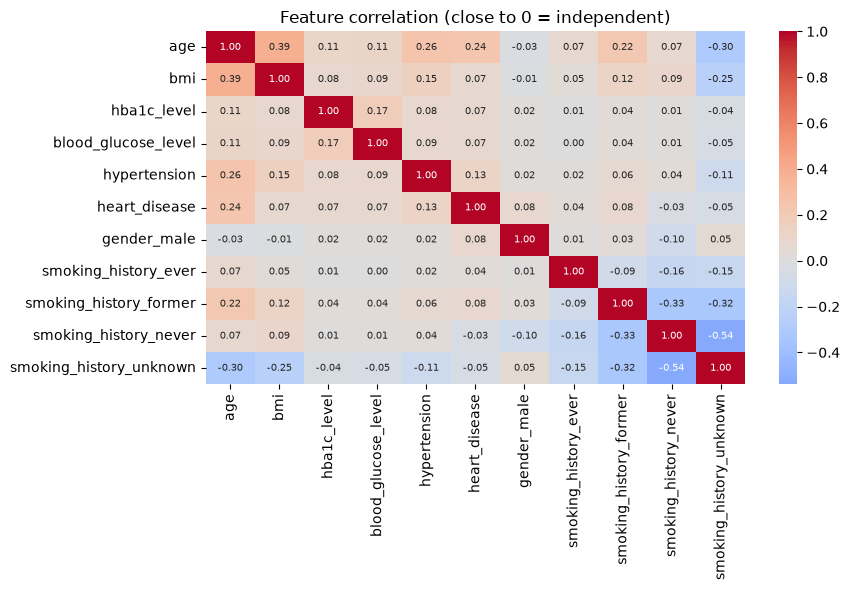

In [3]:
plt.figure(figsize=(9, 6))
sns.heatmap(x_train.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Feature correlation (close to 0 = independent)')
plt.tight_layout(); plt.show()

About two thirds of the feature pairs have a correlation below 0.1 (good for Naive Bayes). The strongest links are between the `smoking_history` columns (one person can be in only one smoking group, r up to 0.54), and `age` with `bmi` (0.38), `hypertension` (0.26) and `heart_disease` (0.24). These break the assumption a little, so the probabilities of Naive Bayes can be off, even when its ranking of patients is good.

### 4. Models and hyperparameters
1. **GaussianNB**: tune `var_smoothing` (adds a small value to the variance so it never becomes 0).
2. **CategoricalNB (binned)**: the 4 continuous columns are cut into bins first (`n_bins`, `strategy`), the 0/1 columns stay as they are. Tune `alpha` (smoothing: avoids zero probability for a category not seen in training).

Scored with **ROC-AUC** (does not depend on the 0.5 threshold, not fooled by imbalance).

In [4]:
models = {
    'GaussianNB': (
        Pipeline([('model', GaussianNB())]),
        {'model__var_smoothing': np.logspace(-9, 0, 10)}
    ),
    'CategoricalNB (binned)': (
        Pipeline([('prep', ColumnTransformer([
                      ('cont', KBinsDiscretizer(encode='ordinal'), cont_cols),
                      ('bin', 'passthrough', bin_cols)])),
                  ('model', CategoricalNB(min_categories=20))]),     # min_categories: room for every bin
        {'prep__cont__n_bins': [5, 10, 15, 20],
         'prep__cont__strategy': ['uniform', 'quantile'],
         'model__alpha': [0.01, 0.1, 1, 10]}
    ),
}

### 5. GridSearchCV on both models

In [5]:
%%time
results, best_models = [], {}

for name, (pipe, params) in models.items():
    grid = GridSearchCV(pipe, params, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True)
    grid.fit(x_train, y_train)

    best = grid.best_estimator_
    proba = best.predict_proba(x_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({'Model': name,
                    'Train_AUC': grid.cv_results_['mean_train_score'][grid.best_index_],
                    'CV_AUC': grid.best_score_,
                    'Test_AUC': roc_auc_score(y_test, proba),
                    'F1 (thr 0.5)': f1_score(y_test, pred),
                    'Recall (thr 0.5)': recall_score(y_test, pred),
                    'Brier': brier_score_loss(y_test, proba),
                    'Best_Params': grid.best_params_})
    best_models[name] = best
    print(f"{name:<24} CV AUC = {grid.best_score_:.4f} | Test AUC = {roc_auc_score(y_test, proba):.4f} | {grid.best_params_}")

GaussianNB               CV AUC = 0.9576 | Test AUC = 0.9534 | {'model__var_smoothing': np.float64(1.0)}
CategoricalNB (binned)   CV AUC = 0.9741 | Test AUC = 0.9708 | {'model__alpha': 0.01, 'prep__cont__n_bins': 20, 'prep__cont__strategy': 'uniform'}
CPU times: total: 16.9 s
Wall time: 40 s


### 6. Compare with Logistic Regression (reference)
Logistic Regression is the usual model for this problem, so we add it as a reference (best params from the logistic notebook).

In [6]:
logit = LogisticRegression(solver='liblinear', C=0.316, penalty='l2').fit(x_train, y_train)
p_logit = logit.predict_proba(x_test)[:, 1]

results.append({'Model': 'Logistic Regression (reference)',
                'Train_AUC': roc_auc_score(y_train, logit.predict_proba(x_train)[:, 1]),
                'CV_AUC': np.nan, 'Test_AUC': roc_auc_score(y_test, p_logit),
                'F1 (thr 0.5)': f1_score(y_test, (p_logit >= 0.5).astype(int)),
                'Recall (thr 0.5)': recall_score(y_test, (p_logit >= 0.5).astype(int)),
                'Brier': brier_score_loss(y_test, p_logit), 'Best_Params': {'C': 0.316, 'penalty': 'l2'}})

results_df = pd.DataFrame(results).sort_values('Test_AUC', ascending=False).reset_index(drop=True)
results_df.drop(columns='Best_Params').round(4)

,Model,Train_AUC,CV_AUC,Test_AUC,F1 (thr 0.5),Recall (thr 0.5),Brier
0,CategoricalNB (binned),0.9743,0.9741,0.9708,0.7634,0.7182,0.0303
1,Logistic Regression (reference),0.9621,NaN,0.9593,0.7252,0.6256,0.0334
2,GaussianNB,0.9576,0.9576,0.9534,0.4938,0.3278,0.0446


**Brier score** = average squared error of the predicted probabilities (lower is better). Naive Bayes multiplies many feature probabilities, so it can be over-confident (probabilities too close to 0 or 1). Check the Brier score and the calibration plot (section 10) to see if that happens here.

### 7. Best Naive Bayes model
Chosen by **CV ROC-AUC** (not by the test set).

In [7]:
nb_df = results_df[results_df['Model'].isin(models)].sort_values('CV_AUC', ascending=False)
best_name = nb_df.iloc[0]['Model']
best_nb = best_models[best_name]

print('Best Naive Bayes:', best_name)
print('Best params     :', nb_df.iloc[0]['Best_Params'])
print('CV AUC          :', round(nb_df.iloc[0]['CV_AUC'], 4))
print('Test AUC        :', round(nb_df.iloc[0]['Test_AUC'], 4))

Best Naive Bayes: CategoricalNB (binned)
Best params     : {'model__alpha': 0.01, 'prep__cont__n_bins': 20, 'prep__cont__strategy': 'uniform'}
CV AUC          : 0.9741
Test AUC        : 0.9708


### 8. Handle imbalance (3 strategies)
1. **Plain**: class prior learned from data (about 9% diabetic), threshold 0.5
2. **Equal priors**: tell the model both classes are equally likely (prior 50% / 50%)
3. **Plain + tuned threshold**: choose the probability cut-off that gives the best F1 (found using CV predictions on the training data only)

(Naive Bayes has no `class_weight`; `priors` is its way to do the same job.)

In [8]:
prior_param = 'model__class_prior' if best_name.startswith('Categorical') else 'model__priors'

plain = clone(best_nb).fit(x_train, y_train)
equal = clone(best_nb).set_params(**{prior_param: [0.5, 0.5]}).fit(x_train, y_train)

# tuned threshold from out-of-fold probabilities
oof = cross_val_predict(clone(best_nb), x_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1_curve)]
print('Best threshold (max CV F1):', round(best_thr, 3))

def scores(name, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'Strategy': name, 'Threshold': round(threshold, 3), 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'ROC_AUC': roc_auc_score(y_test, proba)}

p_plain = plain.predict_proba(x_test)[:, 1]
p_equal = equal.predict_proba(x_test)[:, 1]

pd.DataFrame([scores('1. Plain (0.5)', p_plain, 0.5),
              scores('2. Equal priors (0.5)', p_equal, 0.5),
              scores('3. Plain + tuned threshold', p_plain, best_thr)]).set_index('Strategy').round(4)

Best threshold (max CV F1): 0.691


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
1. Plain (0.5),0.500,0.9607,0.8147,0.7182,0.7634,0.9708
2. Equal priors (0.5),0.500,0.8826,0.4229,0.9033,0.5760,0.9708
3. Plain + tuned threshold,0.691,0.9646,0.9104,0.6651,0.7687,0.9708


### 9. Final model: plain Naive Bayes + tuned threshold
Change `final_threshold` if you prefer more recall (catch more diabetic patients, more false alarms).

              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17510
    Diabetes       0.91      0.67      0.77      1696

    accuracy                           0.96     19206
   macro avg       0.94      0.83      0.87     19206
weighted avg       0.96      0.96      0.96     19206



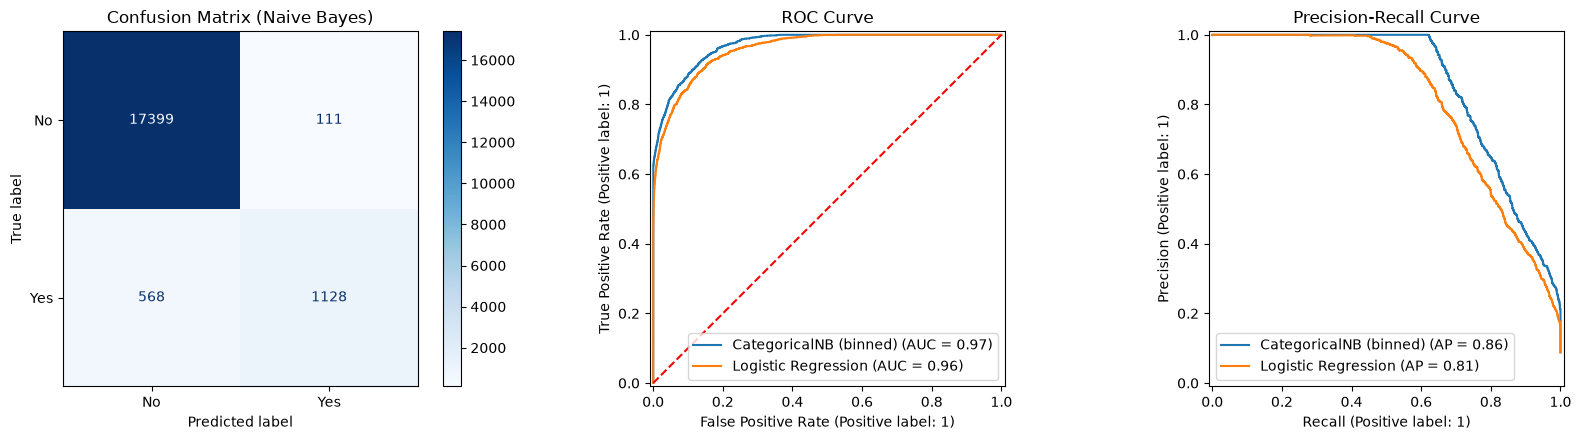

In [9]:
final_threshold = best_thr
final_pred = (p_plain >= final_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['No', 'Yes'], cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix (Naive Bayes)')

RocCurveDisplay.from_predictions(y_test, p_plain, name=best_name, ax=ax[1])
RocCurveDisplay.from_predictions(y_test, p_logit, name='Logistic Regression', ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'r--'); ax[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, p_plain, name=best_name, ax=ax[2])
PrecisionRecallDisplay.from_predictions(y_test, p_logit, name='Logistic Regression', ax=ax[2])
ax[2].set_title('Precision-Recall Curve')
plt.tight_layout(); plt.show()

### 10. Predicted probabilities: Naive Bayes vs Logistic
A well-calibrated model has predicted probabilities that match real frequencies. The plot shows if Naive Bayes is over-confident (points far from the diagonal).

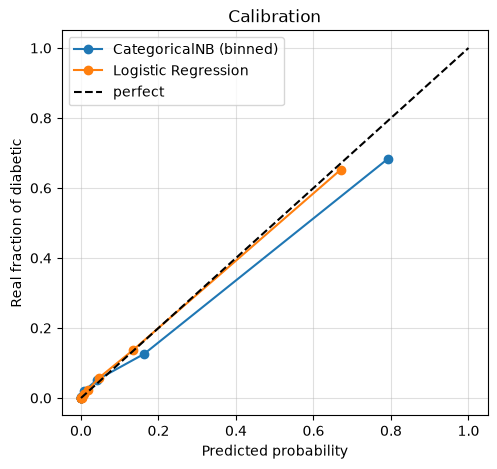

In [10]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(5.5, 5))
for label, p in [(best_name, p_plain), ('Logistic Regression', p_logit)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, 'o-', label=label)
plt.plot([0, 1], [0, 1], 'k--', label='perfect')
plt.xlabel('Predicted probability'); plt.ylabel('Real fraction of diabetic')
plt.title('Calibration'); plt.legend(); plt.grid(alpha=0.4); plt.show()

### 11. Save the model (.pkl)
The model is trained on all data. The threshold is saved with it.

In [11]:
final_nb = clone(best_nb).fit(x, y)

package = {'model': final_nb, 'threshold': float(final_threshold), 'features': list(x.columns), 'name': best_name}
joblib.dump(package, 'naive_bayes_diabetes_model.pkl')
results_df.to_csv('naive_bayes_results.csv', index=False)

#Load and predict
pkg = joblib.load('naive_bayes_diabetes_model.pkl')
proba = pkg['model'].predict_proba(x_test.iloc[:5][pkg['features']])[:, 1]
print('Diabetes probability:', proba.round(3))
print('Prediction          :', (proba >= pkg['threshold']).astype(int))
print('Actual              :', y_test.iloc[:5].values)

Diabetes probability: [0.034 0.    0.    0.39  0.   ]
Prediction          : [0 0 0 0 0]
Actual              : [0 0 0 1 0]


### 12. Download (Google Colab only)

In [12]:
try:
    from google.colab import files
    files.download('naive_bayes_diabetes_model.pkl')
    files.download('naive_bayes_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
